In [1]:
print("Projeto Churn: notebook funcionando!")

Projeto Churn: notebook funcionando!


In [2]:
import pandas as pd

print(pd.__version__)

3.1.1


In [3]:
url = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
)

df = pd.read_csv(url)

df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
total_numerico = pd.to_numeric(df["TotalCharges"], errors="coerce")

problemas = total_numerico.isna()

df.loc[problemas, ["customerID", "tenure", "TotalCharges"]]

,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


In [7]:
df.loc[problemas, "TotalCharges"].map(repr)

488     ' '
753     ' '
936     ' '
1082    ' '
1340    ' '
3331    ' '
3826    ' '
4380    ' '
5218    ' '
6670    ' '
6754    ' '
Name: TotalCharges, dtype: str

In [8]:
exemplo = pd.Series([True, False, True])
exemplo.sum()

np.int64(2)

In [9]:
problemas.sum()

np.int64(11)

In [10]:
df.loc[problemas, "tenure"]

488     0
753     0
936     0
1082    0
1340    0
3331    0
3826    0
4380    0
5218    0
6670    0
6754    0
Name: tenure, dtype: int64

In [11]:
df.loc[problemas, "customerID"]

488     4472-LVYGI
753     3115-CZMZD
936     5709-LVOEQ
1082    4367-NUYAO
1340    1371-DWPAZ
3331    7644-OMVMY
3826    3213-VVOLG
4380    2520-SGTTA
5218    2923-ARZLG
6670    4075-WKNIU
6754    2775-SEFEE
Name: customerID, dtype: str

In [12]:
df["Churn"].value_counts(dropna=False)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [13]:
df["Churn"].value_counts(normalize=True, dropna=False)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [14]:
df["customerID"].duplicated().sum()

np.int64(0)

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## Diagnóstico inicial dos dados

- A base possui 7.043 registros e 21 colunas.
- Não foram encontrados IDs repetidos nem linhas inteiramente duplicadas.
- O pandas não reconheceu valores ausentes na tabela original.
- TotalCharges foi carregada como texto e contém 11 valores formados por um espaço.
- Os 11 registros com esse problema apresentam tenure igual a zero.
- Aproximadamente 26,5% dos clientes da base cancelaram.
- Nenhum registro foi removido e nenhuma coluna original foi alterada.

### Decisão
Investigar e definir o tratamento de TotalCharges antes da modelagem.
Não substituir os espaços por zero sem justificativa.

In [17]:
from sklearn.model_selection import train_test_split

exemplo = [10, 20, 30, 40, 50]

parte_treino, parte_reservada = train_test_split(
    exemplo,
    test_size=0.2,
    random_state=42
)

print("Treino:", parte_treino)
print("Reservada:", parte_reservada)

Treino: [50, 30, 10, 40]
Reservada: [20]


In [18]:
desenvolvimento, teste = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["Churn"]
)

print("Desenvolvimento:", desenvolvimento.shape)
print("Teste:", teste.shape)

Desenvolvimento: (5634, 21)
Teste: (1409, 21)


In [19]:
treino, validacao = train_test_split(
    desenvolvimento,
    test_size=0.25,
    random_state=42,
stratify=desenvolvimento["Churn"])

print("Treino:", treino.shape)
print("Validação:", validacao.shape)

Treino: (4225, 21)
Validação: (1409, 21)


In [20]:
print("Base original:", len(df))
print("Treino:", len(treino))
print("Validação:", len(validacao))
print("Teste:", len(teste))

Base original: 7043
Treino: 4225
Validação: 1409
Teste: 1409


In [21]:
print(treino["Churn"].value_counts(normalize=True, dropna=False))
print(validacao["Churn"].value_counts(normalize=True, dropna=False))

Churn
No     0.734675
Yes    0.265325
Name: proportion, dtype: float64
Churn
No     0.734564
Yes    0.265436
Name: proportion, dtype: float64


In [22]:
ids_treino = set(treino["customerID"])
ids_validacao = set(validacao["customerID"])

print("Clientes em comum:", len(ids_treino.intersection(ids_validacao)))

Clientes em comum: 0


In [23]:
ids_teste = set(teste["customerID"])
print("Validação e teste:", len(ids_validacao.intersection(ids_teste)))
print("Treino e teste:", len(ids_treino.intersection(ids_teste)))

Validação e teste: 0
Treino e teste: 0


## Separação dos dados

- Treino: 4.225 clientes, aproximadamente 60% da base.
- Validação: 1.409 clientes, aproximadamente 20% da base.
- Teste: 1.409 clientes, aproximadamente 20% da base.
- A divisão foi estratificada pela coluna Churn, com random_state=42.
- Não há clientes em comum entre os conjuntos.
- Treino e validação apresentam aproximadamente 26,5% de cancelamentos.

### Regra de uso
O treino será utilizado para ajustar os modelos e o pré-processamento.
A validação será utilizada para comparar alternativas e escolher configurações.
O teste ficará reservado para a avaliação final, sem orientar essas escolhas.

In [24]:
treino["Contract"].value_counts(dropna=False)

Contract
Month-to-month    2326
Two year          1034
One year           865
Name: count, dtype: int64

In [27]:
pd.crosstab(
    treino["Contract"],
    treino["Churn"],
    normalize="index"
)

Churn,No,Yes
Contract,,
Month-to-month,0.569218,0.430782
One year,0.892486,0.107514
Two year,0.974855,0.025145


### Cancelamento por tipo de contrato

No conjunto de treino, a proporção de cancelamentos foi de 43,1% nos contratos mensais, 10,8% nos anuais e 2,5% nos bienais.

Essa associação não demonstra causalidade; diferenças no perfil dos clientes podem contribuir para o resultado.

In [28]:
treino["tenure"].describe()

count    4225.000000
mean       32.294438
std        24.667945
min         0.000000
25%         9.000000
50%        29.000000
75%        56.000000
max        72.000000
Name: tenure, dtype: float64

In [29]:
treino.groupby("Churn")["tenure"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,3104.0,37.521907,24.269930,0.0,15.0,37.0,61.0,72.0
Yes,1121.0,17.819804,19.431418,1.0,2.0,10.0,29.0,72.0


### Cancelamento e tempo de relacionamento

No treino, a mediana do tempo de relacionamento é de 37 meses entre os clientes que não cancelaram e de 10 meses entre os que cancelaram.

Essas medianas representam o centro dos tempos ordenados de cada grupo. Não significam que todos os cancelamentos ocorreram aos 10 meses.

Para calcular a taxa de cancelamento entre clientes com até 10 meses, precisamos dividir o número de cancelamentos nessa faixa pelo total de clientes da mesma faixa.

A diferença observada entre as medianas não demonstra causalidade.

In [30]:
clientes_ate_10 = treino.loc[treino["tenure"] <= 10]

print("Clientes com até 10 meses:", len(clientes_ate_10))

Clientes com até 10 meses: 1181


In [32]:
clientes_ate_10["Churn"].value_counts(dropna=False)

Churn
No     598
Yes    583
Name: count, dtype: int64

In [33]:
clientes_ate_10["Churn"].value_counts(normalize=True, dropna=False)

Churn
No     0.506351
Yes    0.493649
Name: proportion, dtype: float64

### Cancelamento entre clientes com até 10 meses

No treino, entre os 1.181 clientes com até 10 meses de relacionamento, 583 cancelaram, aproximadamente 49,4% desse grupo.

Essa taxa descreve o grupo analisado. Não demonstra que o menor tempo de relacionamento cause cancelamento.

In [35]:
clientes_mais_10 = treino.loc[treino["tenure"] > 10]
print("Clientes com mais de 10 meses:", len(clientes_mais_10))

Clientes com mais de 10 meses: 3044


In [36]:
clientes_mais_10["Churn"].value_counts(normalize=True, dropna=False)

Churn
No     0.823259
Yes    0.176741
Name: proportion, dtype: float64

### Cancelamento entre clientes com mais de 10 meses

No treino, a taxa de cancelamento foi de 17,7% entre os 3.044 clientes com mais de 10 meses, contra 49,4% entre os 1.181 clientes com até 10 meses — diferença de aproximadamente 31,7 pontos percentuais.

O corte de 10 meses foi escolhido de forma exploratória, com base na mediana do grupo que cancelou. Essa associação não demonstra que menor tempo de relacionamento cause cancelamento.

In [37]:
X_train = treino.drop(columns=["Churn", "customerID"])
y_train = treino["Churn"]

print("Entradas:", X_train.shape)
print("Resposta:", y_train.shape)

Entradas: (4225, 19)
Resposta: (4225,)


In [39]:
X_valid = validacao.drop(columns=["Churn", "customerID"])
y_valid = validacao["Churn"]
print("Entradas:", X_valid.shape)
print("Resposta:", y_valid.shape)

Entradas: (1409, 19)
Resposta: (1409,)


In [40]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

previsoes_baseline = baseline.predict(X_valid)

print(previsoes_baseline[:5])

['No' 'No' 'No' 'No' 'No']


In [41]:
from sklearn.metrics import accuracy_score

acuracia = accuracy_score(y_valid, previsoes_baseline)

print("Acurácia:", acuracia)

Acurácia: 0.7345635202271115


In [42]:
from sklearn.metrics import confusion_matrix

matriz = confusion_matrix(
    y_valid,
    previsoes_baseline,
    labels=["No", "Yes"]
)

pd.DataFrame(
    matriz,
    index=["Real: No", "Real: Yes"],
    columns=["Previsto: No", "Previsto: Yes"]
)

,Previsto: No,Previsto: Yes
Real: No,1035,0
Real: Yes,374,0


In [43]:
from sklearn.metrics import recall_score

recall_churn = recall_score(
    y_valid,
    previsoes_baseline,
    pos_label="Yes"
)

print("Recall de cancelamento:", recall_churn)

Recall de cancelamento: 0.0


### Avaliação do baseline

O baseline prevê que nenhum cliente cancela. Ele alcança aproximadamente
73,5% de acurácia porque essa é a proporção de clientes que não cancelaram
na validação.

Entretanto, ele não identifica nenhum dos 374 cancelamentos reais,
resultando em recall de 0% para cancelamento. Portanto, não atende ao
objetivo de identificar esses clientes.

In [44]:
colunas_numericas = X_train.select_dtypes(include="number").columns.tolist()

print(colunas_numericas)

['SeniorCitizen', 'tenure', 'MonthlyCharges']


In [45]:
def converter_total_charges(tabela):
    copia = tabela.copy()
    copia["TotalCharges"] = pd.to_numeric(
        copia["TotalCharges"],
        errors="coerce"
    )
    return copia

treino_convertido = converter_total_charges(X_train)

print("Tipo:", treino_convertido["TotalCharges"].dtype)
print("Ausentes:", treino_convertido["TotalCharges"].isna().sum())

Tipo: float64
Ausentes: 7


In [46]:
colunas_numericas = treino_convertido.select_dtypes(include="number").columns.tolist()
print(colunas_numericas)

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [52]:
from sklearn.impute import SimpleImputer

imputador = SimpleImputer(
    strategy="median",
    add_indicator=True
)

numericos_preenchidos = imputador.fit_transform(
    treino_convertido[colunas_numericas]
)

print("Dimensões:", numericos_preenchidos.shape)
print("Ausentes:", pd.isna(numericos_preenchidos).sum())

Dimensões: (4225, 5)
Ausentes: 0


In [48]:
treino_convertido[["MonthlyCharges", "TotalCharges"]].describe()

,MonthlyCharges,TotalCharges
count,4225.000000,4218.000000
mean,64.776462,2287.835277
std,29.989186,2280.324352
min,18.400000,18.850000
25%,35.750000,386.050000
50%,70.400000,1385.300000
75%,89.750000,3832.900000
max,118.750000,8684.800000


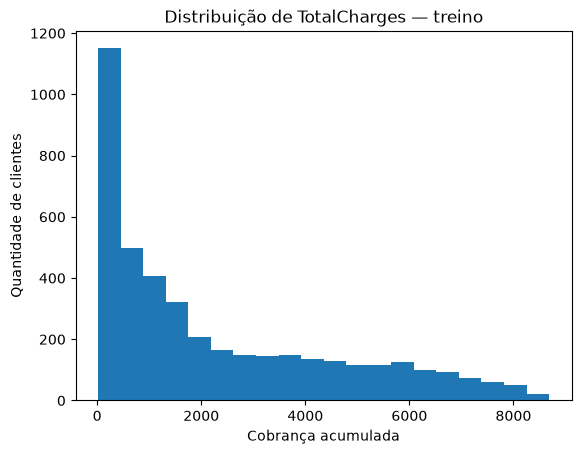

In [49]:
import matplotlib.pyplot as plt

plt.hist(treino_convertido["TotalCharges"].dropna(), bins=20)
plt.xlabel("Cobrança acumulada")
plt.ylabel("Quantidade de clientes")
plt.title("Distribuição de TotalCharges — treino")
plt.show()

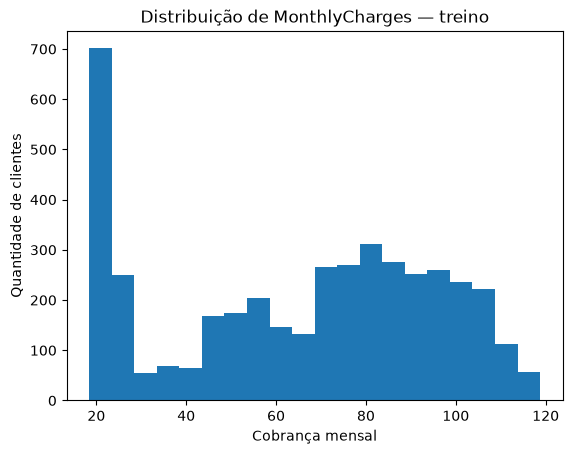

In [50]:
plt.hist(treino_convertido["MonthlyCharges"].dropna(), bins=20)
plt.xlabel("Cobrança mensal")
plt.ylabel("Quantidade de clientes")
plt.title("Distribuição de MonthlyCharges — treino")
plt.show()

### Distribuição das cobranças no treino

TotalCharges apresenta maior concentração nas faixas de menor cobrança
acumulada e uma cauda à direita, com menos clientes nos valores elevados.

MonthlyCharges apresenta forte concentração próxima de 20 e outra região
de concentração, mais espalhada, aproximadamente entre 70 e 100.

Os gráficos descrevem as distribuições, mas não explicam suas causas
nem justificam, sozinhos, remover valores elevados.

In [51]:
treino_convertido.loc[
    treino_convertido["TotalCharges"].isna(),
    ["tenure", "MonthlyCharges", "TotalCharges"]
]

,tenure,MonthlyCharges,TotalCharges
6670,0,73.35,NaN
3826,0,25.35,NaN
3331,0,19.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
4380,0,20.00,NaN
6754,0,61.90,NaN


In [53]:
from sklearn.preprocessing import StandardScaler

exemplo_escala = pd.DataFrame({"valor": [10, 20, 30]})

escalador = StandardScaler()
valores_padronizados = escalador.fit_transform(exemplo_escala)

print(valores_padronizados)

[[-1.22474487]
 [ 0.        ]
 [ 1.22474487]]


In [54]:
from sklearn.pipeline import Pipeline

pipeline_numerico = Pipeline([
    ("imputacao", SimpleImputer(strategy="median", add_indicator=True)),
    ("escala", StandardScaler())
])

numericos_transformados = pipeline_numerico.fit_transform(
    treino_convertido[colunas_numericas]
)

print("Dimensões:", numericos_transformados.shape)
print("Ausentes:", pd.isna(numericos_transformados).sum())

Dimensões: (4225, 5)
Ausentes: 0


## Preparação dos dados — mapa de implementação

### Entradas e resposta
- X_train e X_valid contêm as características dos clientes.
- y_train e y_valid contêm Churn.
- Churn e customerID foram excluídos das entradas.
- O teste continua reservado.

### Componentes já demonstrados
1. converter_total_charges: converte TotalCharges para número,
   transformando textos inválidos em ausentes.
2. pipeline_numerico: preenche ausentes com medianas aprendidas no treino,
   adiciona indicadores de ausência e padroniza os valores.

### Dados intermediários
- treino_convertido: entradas do treino após a conversão de TotalCharges.
- numericos_transformados: resultado do pipeline aplicado somente
  às colunas numéricas. Ainda não contém as categorias.

### O que falta integrar
- Preparação das colunas categóricas.
- União dos tratamentos numéricos e categóricos.
- Conversão e pré-processamento conectados à regressão logística.

### Regra de aprendizado
As estatísticas dos tratamentos serão aprendidas somente no treino.
Na validação, serão reutilizadas sem novo ajuste.

A imputação pela mediana com indicador é uma escolha inicial de modelagem,
não uma recuperação da cobrança verdadeira.

In [55]:
colunas_categoricas = treino_convertido.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

print(colunas_categoricas)
print("Quantidade:", len(colunas_categoricas))

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Quantidade: 15


In [56]:
from sklearn.preprocessing import OneHotEncoder

exemplo_contratos = pd.DataFrame({
    "Contract": ["Mensal", "Anual", "Mensal"]
})

codificador = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

categorias_transformadas = codificador.fit_transform(exemplo_contratos)

pd.DataFrame(
    categorias_transformadas,
    columns=codificador.get_feature_names_out()
)

,Contract_Anual,Contract_Mensal
0,0.0,1.0
1,1.0,0.0
2,0.0,1.0


In [57]:
codificador_categorico = OneHotEncoder(handle_unknown="ignore")

categoricas_transformadas = codificador_categorico.fit_transform(
    treino_convertido[colunas_categoricas]
)

print("Antes:", treino_convertido[colunas_categoricas].shape)
print("Depois:", categoricas_transformadas.shape)

Antes: (4225, 15)
Depois: (4225, 41)


In [58]:
from sklearn.compose import ColumnTransformer

preprocessador = ColumnTransformer([
    ("numericas", pipeline_numerico, colunas_numericas),
    ("categoricas", codificador_categorico, colunas_categoricas)
])

entradas_transformadas = preprocessador.fit_transform(treino_convertido)

print("Dimensões:", entradas_transformadas.shape)

Dimensões: (4225, 46)


In [59]:
from sklearn.preprocessing import FunctionTransformer

conversor = FunctionTransformer(converter_total_charges)

entradas_convertidas = conversor.transform(X_train)

print(entradas_convertidas["TotalCharges"].dtype)

float64


In [60]:
from sklearn.linear_model import LogisticRegression

modelo_logistico = Pipeline([
    ("conversao", conversor),
    ("preprocessamento", preprocessador),
    ("modelo", LogisticRegression(max_iter=1000))
])

modelo_logistico.fit(X_train, y_train)

print("Treinamento concluído.")

Treinamento concluído.


In [61]:
previsoes_logistica = modelo_logistico.predict(X_valid)

print("Quantidade:", len(previsoes_logistica))
print("Primeiras previsões:", previsoes_logistica[:10])

Quantidade: 1409
Primeiras previsões: ['Yes' 'Yes' 'Yes' 'Yes' 'No' 'No' 'No' 'No' 'Yes' 'No']


In [62]:
acuracia_logistica = accuracy_score(y_valid, previsoes_logistica)

recall_logistica = recall_score(
    y_valid,
    previsoes_logistica,
    pos_label="Yes"
)

print("Acurácia:", acuracia_logistica)
print("Recall de cancelamento:", recall_logistica)

Acurácia: 0.8026969481902059
Recall de cancelamento: 0.5347593582887701


In [63]:
matriz_logistica = confusion_matrix(
    y_valid,
    previsoes_logistica,
    labels=["No", "Yes"]
)

pd.DataFrame(
    matriz_logistica,
    index=["Real: No", "Real: Yes"],
    columns=["Previsto: No", "Previsto: Yes"]
)

,Previsto: No,Previsto: Yes
Real: No,931,104
Real: Yes,174,200


In [64]:
from sklearn.metrics import precision_score

precisao_logistica = precision_score(
    y_valid,
    previsoes_logistica,
    pos_label="Yes"
)

print("Precisão dos alertas:", precisao_logistica)

Precisão dos alertas: 0.6578947368421053


## Regressão logística — avaliação na validação

O modelo obteve aproximadamente 80,3% de acurácia, contra 73,5% do baseline.

Identificou 200 dos 374 cancelamentos reais, com recall de 53,5%.
Dos 304 alertas de cancelamento, 200 estavam corretos, com precisão de 65,8%.

Foram observados 174 cancelamentos não identificados e 104 alertas incorretos.

O resultado supera o baseline nas métricas avaliadas, mas ainda não demonstra
viabilidade operacional. Precisamos comparar alternativas e considerar
os custos dos erros. O teste permanece reservado.

In [65]:
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier

modelo_arvore = Pipeline([
    ("conversao", clone(conversor)),
    ("preprocessamento", clone(preprocessador)),
    ("modelo", DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ))
])

modelo_arvore.fit(X_train, y_train)

print("Árvore treinada.")

Árvore treinada.


In [66]:
previsoes_arvore = modelo_arvore.predict(X_valid)
print("Quantidade:", len(previsoes_arvore))


Quantidade: 1409


In [68]:
acuracia_arvore = accuracy_score(y_valid, previsoes_arvore)
recall_arvore = recall_score(y_valid, previsoes_arvore, pos_label="Yes")
precisao_arvore = precision_score(y_valid, previsoes_arvore, pos_label="Yes")

print("Acuracia dos clientes:", acuracia_arvore)
print("Recall dos cancelamentos:", recall_arvore)
print("Precisão dos alertas:", precisao_arvore)

Acuracia dos alertas: 0.794180269694819
Recall dos alertas: 0.45454545454545453
Precisão dos alertas: 0.6640625


In [69]:
matriz_arvore = confusion_matrix(
    y_valid,
    previsoes_arvore,
    labels=["No", "Yes"]
)

pd.DataFrame(
    matriz_arvore,
    index=["Real: No", "Real: Yes"],
    columns=["Previsto: No", "Previsto: Yes"]
)

,Previsto: No,Previsto: Yes
Real: No,949,86
Real: Yes,204,170


### Comparação inicial dos modelos

Na validação, a árvore apresentou precisão de 66,4%, contra 65,8%
da regressão logística, uma diferença pequena de aproximadamente
0,6 ponto percentual.

A árvore gerou 18 alertas incorretos a menos, mas deixou passar
30 cancelamentos a mais que a logística.

A escolha depende dos custos dos dois tipos de erro e da eficácia
da ação de retenção. Sem essas informações, não podemos declarar
um vencedor operacional.

In [70]:
probabilidades_logistica = modelo_logistico.predict_proba(X_valid)

print("Ordem das classes:", modelo_logistico.classes_)
print("Primeiros cinco clientes:")
print(probabilidades_logistica[:5])

Ordem das classes: ['No' 'Yes']
Primeiros cinco clientes:
[[0.3548796  0.6451204 ]
 [0.26908256 0.73091744]
 [0.34114278 0.65885722]
 [0.39078353 0.60921647]
 [0.97968557 0.02031443]]


In [71]:
probabilidade_churn = probabilidades_logistica[:, 1]

print(probabilidade_churn[:5])
print("Quantidade:", len(probabilidade_churn))

[0.6451204  0.73091744 0.65885722 0.60921647 0.02031443]
Quantidade: 1409


In [72]:
import numpy as np

limiar = 0.50

previsoes_limiar_050 = np.where(
    probabilidade_churn >= limiar,
    "Yes",
    "No"
)

print(previsoes_limiar_050[:5])

['Yes' 'Yes' 'Yes' 'Yes' 'No']


In [74]:
limiar = 0.30

previsoes_limiar_030 = np.where(
    probabilidade_churn >= limiar,
    "Yes",
    "No"
)

print(previsoes_limiar_030[:5])

print("Recall:", recall_score(
    y_valid, previsoes_limiar_030, pos_label="Yes"
))

print("Precisão:", precision_score(
    y_valid, previsoes_limiar_030, pos_label="Yes"
))

['Yes' 'Yes' 'Yes' 'Yes' 'No']
Recall: 0.7513368983957219
Precisão: 0.5383141762452107


In [75]:
matriz_limiar = confusion_matrix(
    y_valid,
    previsoes_limiar_030,
    labels=["No", "Yes"]
)

pd.DataFrame(
    matriz_limiar,
    index=["Real: No", "Real: Yes"],
    columns=["Previsto: No", "Previsto: Yes"]
)

,Previsto: No,Previsto: Yes
Real: No,794,241
Real: Yes,93,281


### Efeito da redução do limiar

Na validação, reduzir o limiar de 0,50 para 0,30 permitiu identificar
81 cancelamentos adicionais e reduziu os cancelamentos não identificados
de 174 para 93.

Em contrapartida, surgiram 137 alertas incorretos adicionais.
O total de alertas aumentou de 304 para 522, enquanto a precisão
caiu de 65,8% para 53,8%.

Ainda não podemos escolher o melhor corte sem conhecer a capacidade
operacional, os custos dos erros e a eficácia da ação de retenção.